<a href="https://colab.research.google.com/github/marcelfollyagbo1-ui/panier-perdu/blob/main/Portfolio_Financeipynb.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

        Rendement cumulé (%)  Volatilité (%)  Drawdown max (%)
Ticker                                                        
AAPL                   137.2            28.0             -33.4
QQQ                     83.6            23.1             -35.1
VOO                     76.2            16.9             -24.5


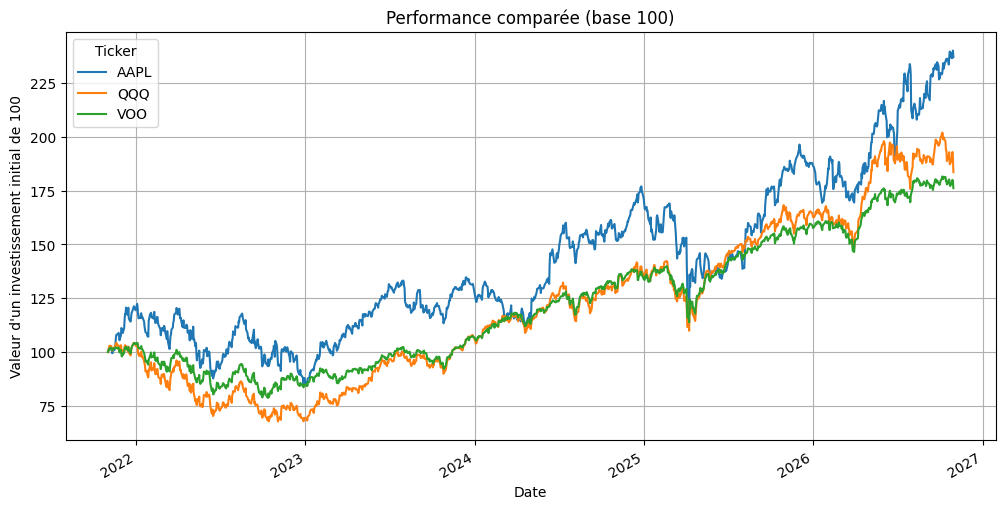

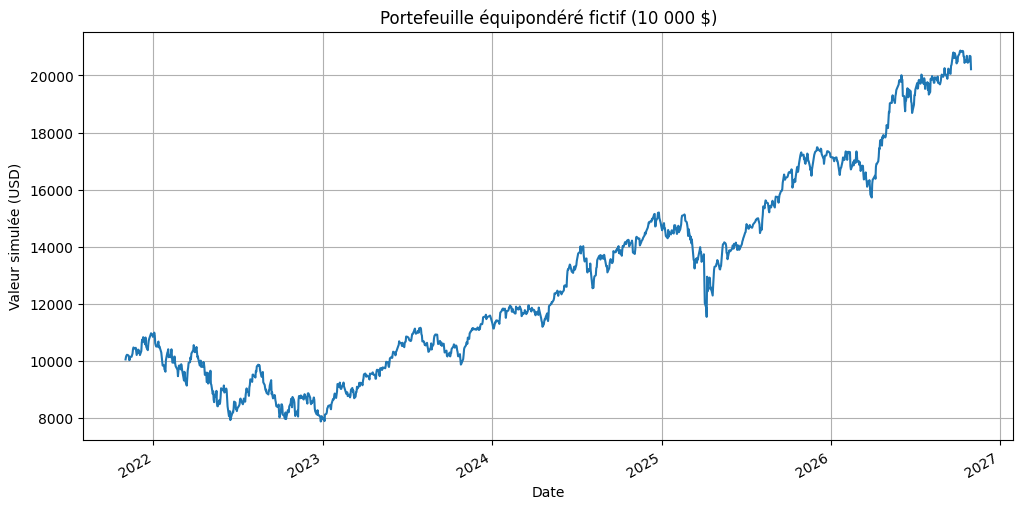

Valeur finale : 20219 USD


In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import yfinance as yf
import matplotlib.pyplot as plt

# 1. Données : cours de clôture ajustés, 5 ans
actifs = ["VOO", "QQQ", "AAPL"]
cours = yf.download(actifs, period="5y", auto_adjust=True, progress=False)["Close"]
cours = cours.dropna(how="all")

# 2. Rendements quotidiens
rendements = cours.pct_change().dropna()

# 3. Performance totale (%)
perf_cumulee = (cours.iloc[-1] / cours.iloc[0] - 1) * 100

# 4. Risque : volatilité annualisée (%) et drawdown maximal (%)
volatilite = rendements.std() * np.sqrt(252) * 100
valeurs = (1 + rendements).cumprod()
drawdown = (valeurs / valeurs.cummax() - 1).min() * 100

# 5. Tableau récapitulatif
tableau = pd.DataFrame({
    "Rendement cumulé (%)": perf_cumulee,
    "Volatilité (%)": volatilite,
    "Drawdown max (%)": drawdown,
}).round(1)
print(tableau)

# 6. Graphique en base 100
(cours / cours.iloc[0] * 100).plot(figsize=(12, 6), title="Performance comparée (base 100)")
plt.ylabel("Valeur d'un investissement initial de 100")
plt.grid(True)
plt.show()

# 7. Portefeuille équipondéré fictif de 10 000 $
capital = 10_000
valeur_portefeuille = capital * (1 + rendements.mean(axis=1)).cumprod()
valeur_portefeuille.plot(figsize=(12, 6), title="Portefeuille équipondéré fictif (10 000 $)")
plt.ylabel("Valeur simulée (USD)")
plt.grid(True)
plt.show()
print("Valeur finale :", round(valeur_portefeuille.iloc[-1]), "USD")